# Task 1 · Decoding & Evaluation — BERT-BLEU₄

This notebook generates captions from saved LoRA adapters and scores them with **BERT-BLEU₄** (the primary metric).
It covers three phases of the experiment plan:

| Phase | Question | Adapters | Images |
|---|---|---|---|
| **A · Decoding** | Can a better decoding strategy fix the length penalty without any training? | zero-shot, E3, E4 | 200 val (same as E0–E5) |
| **B · Data scaling** | How does the score grow with the amount of training data? | E8 checkpoints (25/50/75/100%) | 200 val |
| **C · Final test** | Is the final model really better, on images never used for any decision? | finalists | 1000 test (disjoint from val) |

**Why decoding matters here.** BERT-BLEU₄ $= LP \cdot \exp(\tfrac14\sum\log P_n)$. All runs so far lose ~15% of their score to
the length penalty (mean LP ≈ 0.85), while the content term differs by only ~0.005 between runs. Decoding changes caption length
directly, and needs no retraining.

**Decoding strategies**

| Name | What it does |
|---|---|
| `greedy` | pick the most likely token at every step (what E0–E5 used) |
| `beam4_lpX` | keep the 4 best partial captions; beam score = log p / length^X, so X < 1 favours shorter and X > 1 longer captions |
| `mbr6` | Minimum Bayes Risk: greedy + 5 sampled captions, keep the one that agrees most with the others (BERT-BLEU₄ between candidates). No reference is used, so this is a legitimate decoding method |

Generated captions are cached in `OUT_DIR/predictions/`, so a Kaggle restart resumes where it stopped.

## 1. Setup

In [1]:
!pip install -q -U transformers accelerate peft qwen-vl-utils nltk torchao   # PEFT needs a recent torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 77.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 85.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.6/69.6 kB 2.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently 

In [2]:
import json, math, random, re, shutil, time
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from peft import PeftModel
from qwen_vl_utils import process_vision_info
from transformers import AutoModel, AutoProcessor, AutoTokenizer, Qwen2_5_VLForConditionalGeneration

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


In [3]:
# =====================================================================
# Paths: edit these
# =====================================================================
DATA_ROOT = Path('/temp/VRSBench')
VAL_JSON = DATA_ROOT / 'hf_files' / 'VRSBench_EVAL_Cap.json'
VAL_IMAGE_DIR = DATA_ROOT / 'Images_val'
OUT_DIR = Path('/kaggle/working/decode_eval')

# name -> folder containing the adapter files (any file names like 'adapter_config (4).json' are fine).
# Missing folders are skipped, so the E8 entries can stay here before E8 is trained.
ADAPTERS = {
    'E3': '/kaggle/input/vrsbench-adapters/E3',
    'E4': '/kaggle/input/vrsbench-adapters/E4',
    'E8@25%': '/kaggle/input/e8-full-data-train/E8/checkpoint-25pct',
    'E8@50%': '/kaggle/input/e8-full-data-train/E8/checkpoint-50pct',
    'E8@75%': '/kaggle/input/e8-full-data-train/E8/checkpoint-75pct',
    'E8': '/kaggle/input/e8-full-data-train/E8/final',
}
# Saved E3 predictions, used to check that this notebook reproduces the original E3 evaluation
LEGACY_E3_PREDICTIONS = '/kaggle/input/vrsbench-adapters/E3/predictions.json'
# Optional: a folder with predictions/ + timings.json from an earlier run (e.g. the downloaded decode_eval folder
# uploaded as a Kaggle dataset). Copied into OUT_DIR, so only missing or broken captions are generated again.
PREVIOUS_RESULTS = None

# =====================================================================
# Settings: identical to E0-E5 unless stated
# =====================================================================
MODEL_ID = 'Qwen/Qwen2.5-VL-3B-Instruct'
PROMPT = 'Describe the image in detail.'
MIN_PIXELS, MAX_PIXELS = 224 * 224, 448 * 448
MAX_NEW_TOKENS = 128
VAL_SEED, VAL_N = 2026, 200      # reproduces the exact 200 val images of E0-E5
TEST_SEED, TEST_N = 7, 1000      # held-out images, disjoint from val, for the final numbers
GEN_BATCH = 8                    # captions generated in parallel
MAX_SEQUENCES = 16               # beams/samples x images per generate() call (memory cap)
MBR_SAMPLES = 5                  # MBR candidates = greedy + 5 samples
SAMPLING = dict(do_sample=True, temperature=0.7, top_p=0.9)   # Qwen's default temperature is 1e-6 (= greedy)
BERT_MODEL = 'bert-base-uncased' # BERT-BLEU4 encoder, same as compare_experiments.ipynb
N_BOOT = 2000

GEN_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
# 2 GPUs: Qwen generates on GPU 0, the BERT scorer lives on GPU 1
SCORER_DEVICE = torch.device('cuda:1' if torch.cuda.device_count() > 1 else GEN_DEVICE)
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / 'predictions').mkdir(exist_ok=True)
print('generation on', GEN_DEVICE, '| scoring on', SCORER_DEVICE)

if PREVIOUS_RESULTS:
    prev = Path(PREVIOUS_RESULTS)
    for f in list(prev.glob('predictions/*.json')) + [prev / 'timings.json']:
        target = OUT_DIR / f.relative_to(prev)
        if f.exists() and not target.exists():
            shutil.copy(f, target)
    print('cached prediction files:', len(list((OUT_DIR / 'predictions').glob('*.json'))))

generation on cuda:0 | scoring on cuda:1


## 2. Data

The E0–E5 notebooks sampled their 200 validation images with `random.Random(2026).sample(val_records, 200)`.
Rebuilding `val_records` in the same order and repeating that call gives exactly the same images.
The test split is sampled from the remaining 9,150 images, so no image used for choosing a decoding strategy or checkpoint
is reused for the final numbers.

In [4]:
if not VAL_IMAGE_DIR.exists() or not VAL_JSON.exists():
    from huggingface_hub import hf_hub_download
    from zipfile import ZipFile
    hf_hub_download('xiang709/VRSBench', 'VRSBench_EVAL_Cap.json', repo_type='dataset', local_dir=VAL_JSON.parent)
    val_zip = hf_hub_download('xiang709/VRSBench', 'Images_val.zip', repo_type='dataset', local_dir=VAL_JSON.parent)
    VAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    with ZipFile(val_zip) as z:
        z.extractall(VAL_IMAGE_DIR)
    Path(val_zip).unlink()

image_path = {p.name: str(p) for p in VAL_IMAGE_DIR.rglob('*') if p.suffix.lower() in {'.png', '.jpg', '.jpeg'}}
val_records = [
    {'image_id': Path(r['image_id']).name, 'caption': r['ground_truth'].strip(),
     'image_path': image_path[Path(r['image_id']).name]}
    for r in json.loads(VAL_JSON.read_text())
    if r.get('image_id') and r.get('ground_truth') and Path(r['image_id']).name in image_path
]

val_split = random.Random(VAL_SEED).sample(val_records, VAL_N)
val_ids = {r['image_id'] for r in val_split}
test_split = random.Random(TEST_SEED).sample([r for r in val_records if r['image_id'] not in val_ids], TEST_N)
SPLITS = {'val': val_split, 'test': test_split}

print(f'{len(val_records):,} caption records | val {len(val_split)} | test {len(test_split)} (disjoint)')
print('first val image:', val_split[0]['image_id'])

VRSBench_EVAL_Cap.json:   0%|          | 0.00/4.81M [00:00<?, ?B/s]

Images_val.zip: reconstructing file:   0%|          |  0.00B / 3.98GB            

Images_val.zip: downloading bytes:           |  0.00B            

9,350 caption records | val 200 | test 1000 (disjoint)
first val image: P1386_0046.png


## 3. Model and adapters

The fp16 base model is loaded once; every adapter is attached to it by name, and `set_adapter` switches between them.
**zero-shot** runs the base model with adapters disabled.

Memory layout: GPU 0 holds Qwen (~7.5 GB + generation), GPU 1 only the BERT scorer (~0.5 GB). The cell prints both.
Re-running this cell is safe: the previous copy is freed first. If a CUDA out-of-memory error ever leaves memory stuck
(`nvidia-smi` shows ~15 GB with 0% utilisation), restart the kernel and run the notebook top to bottom once.

In [5]:
import gc

# Re-running this cell must not stack a second 7.5 GB copy on GPU 0: drop the previous one first
for name in ('model', 'base'):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()


def gpu_report():
    for i in range(torch.cuda.device_count()):
        print(f'GPU {i}: {torch.cuda.memory_allocated(i) / 1024**3:.1f} GB in use, '
              f'{torch.cuda.memory_reserved(i) / 1024**3:.1f} GB reserved')


processor = AutoProcessor.from_pretrained(MODEL_ID, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS)
processor.tokenizer.padding_side = 'left'   # generation: every prompt must end at the same position
base = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, attn_implementation='sdpa', low_cpu_mem_usage=True,
).to(GEN_DEVICE)



def standard_adapter_dir(folder, name):
    # PEFT expects adapter_config.json + adapter_model.safetensors; copy renamed files into that layout if needed
    folder = Path(folder)
    config = sorted(folder.rglob('*adapter_config*.json'))
    weights = sorted(folder.rglob('*adapter_model*.safetensors'))
    assert len(config) == 1 and len(weights) == 1, f'{folder}: expected one adapter config + one weights file'
    config, weights = config[0], weights[0]
    if config.name == 'adapter_config.json' and weights.name == 'adapter_model.safetensors' and config.parent == weights.parent:
        return config.parent
    fixed = OUT_DIR / 'adapters' / name
    fixed.mkdir(parents=True, exist_ok=True)
    shutil.copy(config, fixed / 'adapter_config.json')
    shutil.copy(weights, fixed / 'adapter_model.safetensors')
    return fixed


model = None
for name, folder in ADAPTERS.items():
    if not Path(folder).exists():
        print(f'skip {name}: {folder} not found')
        continue
    path = standard_adapter_dir(folder, name)
    if model is None:
        model = PeftModel.from_pretrained(base, path, adapter_name=name)
    else:
        model.load_adapter(path, adapter_name=name)
    print(f'loaded {name}')
model.eval()
LOADED = list(model.peft_config)
gpu_report()   # expected: GPU 0 ~7.5 GB, GPU 1 ~0 GB

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

loaded E3
loaded E4
loaded E8@25%
loaded E8@50%
loaded E8@75%
loaded E8
GPU 0: 7.4 GB in use, 7.6 GB reserved
GPU 1: 0.0 GB in use, 0.0 GB reserved


## 4. Caption generation

`generate` captions a batch of images with one adapter and any Hugging Face decoding arguments.
`predict` runs a whole split for one (adapter, decoding) pair and caches the result on disk.

In [6]:
from contextlib import contextmanager

DECODING = {
    'greedy':      dict(do_sample=False, num_beams=1),
    'beam4_lp0.6': dict(do_sample=False, num_beams=4, length_penalty=0.6),
    'beam4_lp1.0': dict(do_sample=False, num_beams=4, length_penalty=1.0),
    'beam4_lp1.4': dict(do_sample=False, num_beams=4, length_penalty=1.4),
    'mbr6':        None,   # special case, see caption_batch()
}


@torch.no_grad()
def _generate_once(samples, adapter, decoding):
    messages = [[{'role': 'user', 'content': [{'type': 'image', 'image': s['image_path']},
                                              {'type': 'text', 'text': PROMPT}]}] for s in samples]
    texts = [processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in messages]
    images, _ = process_vision_info(messages)
    inputs = processor(text=texts, images=images, padding=True, return_tensors='pt').to(GEN_DEVICE)

    if adapter == 'zero-shot':
        context = model.disable_adapter()
    else:
        model.set_adapter(adapter)
        context = nullcontext()
    with context:
        # fp16 can overflow to NaN/inf logits on rare images. Greedy survives that (argmax), but sampling crashes the
        # GPU with "device-side assert triggered". remove_invalid_values replaces NaN/inf before sampling.
        output = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, remove_invalid_values=True, **decoding)

    captions = processor.batch_decode(output[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    captions = [c.strip() for c in captions]
    per_image = decoding.get('num_return_sequences', 1)
    if per_image == 1:
        return captions
    return [captions[i * per_image:(i + 1) * per_image] for i in range(len(samples))]


def batches(items, size):
    for i in range(0, len(items), size):
        yield items[i:i + size]


OOM_ERRORS = tuple(e for e in (getattr(torch, 'OutOfMemoryError', None), getattr(torch, 'AcceleratorError', None)) if e)


def generate(samples, adapter, **decoding):
    # Caption a batch; on CUDA out-of-memory, free the cache and retry the two halves separately
    try:
        return _generate_once(samples, adapter, decoding)
    except OOM_ERRORS as e:
        if 'out of memory' not in str(e) or len(samples) == 1:
            raise
    # Retry outside the except block, so the failed attempt's tensors (held by the traceback) are freed first
    gc.collect()
    torch.cuda.empty_cache()
    half = len(samples) // 2
    print(f'  out of memory on {len(samples)} images -> retrying as {half} + {len(samples) - half}')
    return generate(samples[:half], adapter, **decoding) + generate(samples[half:], adapter, **decoding)


def images_per_call(decoding):
    # Beam search and sampling run several sequences per image: keep the total per call <= MAX_SEQUENCES
    per_image = max(decoding.get('num_beams', 1), decoding.get('num_return_sequences', 1))
    return max(1, min(GEN_BATCH, MAX_SEQUENCES // per_image))


def is_degenerate(caption):
    # fp16 overflow -> NaN logits: greedy then emits '!!!!...' (token 0), sampling emits random multilingual tokens
    english_words = re.findall(r'[a-z]+', caption.lower())
    return len(english_words) < 5 or '!!!!' in caption or bool(re.search(r'[^\x00-\x7f‘’“”–—°]', caption))


@contextmanager
def vision_in_fp32():
    # Last resort for an image that overflows even on its own: run the vision encoder in fp32 (+1.3 GB, slower)
    visual = base.model.visual
    dtypes = {name: p.dtype for name, p in visual.named_parameters()}
    visual.float()
    try:
        yield
    finally:
        for name, p in visual.named_parameters():
            p.data = p.data.to(dtypes[name])


def caption_batch(batch, adapter, decoding, greedy=None, seed=0):
    if decoding != 'mbr6':
        return generate(batch, adapter, **DECODING[decoding])
    torch.manual_seed(seed)   # MBR samples are random: a fixed seed makes a re-run give the same captions
    sampled = generate(batch, adapter, num_return_sequences=MBR_SAMPLES, **SAMPLING)
    return [mbr_pick([greedy[s['image_id']]] + cands) for s, cands in zip(batch, sampled)]


REPAIR_TRIED = set()   # (adapter, decoding, image) already retried in this session: never retry twice


def repair(samples, captions, adapter, decoding, greedy=None):
    # Batched fp16 generation (left padding) occasionally overflows into NaN logits and returns a broken caption.
    # The E0-E5 notebooks captioned one image at a time and never hit this, so a broken caption is regenerated
    # for that image alone; if it is still broken, once more with the vision encoder in fp32.
    repaired = 0
    for i, (s, caption) in enumerate(zip(samples, captions)):
        if not is_degenerate(caption) or (adapter, decoding, s['image_id']) in REPAIR_TRIED:
            continue
        REPAIR_TRIED.add((adapter, decoding, s['image_id']))
        new = caption_batch([s], adapter, decoding, greedy, seed=i)[0]
        if is_degenerate(new):
            with vision_in_fp32():
                new = caption_batch([s], adapter, decoding, greedy, seed=i)[0]
        print(f'  repaired {s["image_id"]}: {caption[:30]!r} -> {new[:50]!r}')
        captions[i] = new
        repaired += 1
    return repaired


def load_timings():
    path = OUT_DIR / 'timings.json'
    return json.loads(path.read_text()) if path.exists() else {}


def predict(adapter, decoding, split):
    # Captions for every image of `split`, generated once and cached on disk
    name = f'{adapter}__{decoding}__{split}'
    path = OUT_DIR / 'predictions' / f'{name}.json'
    samples = SPLITS[split]
    greedy = None
    if decoding == 'mbr6':   # MBR candidates include the greedy caption
        greedy = {p['image_id']: p['prediction'] for p in predict(adapter, 'greedy', split)}

    if path.exists():
        rows = json.loads(path.read_text())
        assert [r['image_id'] for r in rows] == [s['image_id'] for s in samples], f'{path.name}: different images'
        captions = [r['prediction'] for r in rows]
        if repair(samples, captions, adapter, decoding, greedy):   # files cached before the repair step existed
            rows = [{**r, 'prediction': c} for r, c in zip(rows, captions)]
            path.write_text(json.dumps(rows, indent=1, ensure_ascii=False))
        return rows

    start = time.perf_counter()
    size = images_per_call({'num_return_sequences': MBR_SAMPLES} if decoding == 'mbr6' else DECODING[decoding])
    captions = []
    for k, batch in enumerate(batches(samples, size)):
        captions += caption_batch(batch, adapter, decoding, greedy, seed=k)
        if (k + 1) % 10 == 0:
            print(f'  {name}: {len(captions)}/{len(samples)}')
    repair(samples, captions, adapter, decoding, greedy)
    seconds = (time.perf_counter() - start) / len(samples)
    if decoding == 'mbr6':
        seconds += load_timings()[f'{adapter}__greedy__{split}']   # MBR needs the greedy caption too

    rows = [{'image_id': s['image_id'], 'reference': s['caption'], 'prediction': c} for s, c in zip(samples, captions)]
    path.write_text(json.dumps(rows, indent=1, ensure_ascii=False))
    timings = load_timings()
    timings[name] = seconds
    (OUT_DIR / 'timings.json').write_text(json.dumps(timings, indent=1))
    print(f'{name}: {seconds:.2f} s/image')
    return rows

## 5. BERT-BLEU₄ scorer

Same definition and implementation choices as `compare_experiments.ipynb`, so the numbers are directly comparable:
`bert-base-uncased` last layer, each n-gram encoded on its own and mean-pooled, n-gram sets, word-level lengths, α = 0.5.
Embeddings are cached, because references and many n-grams repeat across runs.

In [7]:
class BertBleu4:
    TOKEN_RE = re.compile(r"[a-z0-9]+(?:['-][a-z0-9]+)*")

    def __init__(self, model_name, device, alpha=0.5, max_n=4, batch_size=512):
        self.tok = AutoTokenizer.from_pretrained(model_name)
        self.bert = AutoModel.from_pretrained(model_name).to(device).eval()
        self.device, self.alpha, self.max_n, self.batch_size = device, alpha, max_n, batch_size
        self.cache = {}

    def words(self, text):
        return self.TOKEN_RE.findall(text.lower())

    def ngram_sets(self, text):
        w = self.words(text)
        return [sorted({' '.join(w[i:i + n]) for i in range(len(w) - n + 1)}) for n in range(1, self.max_n + 1)]

    @torch.no_grad()
    def embed_missing(self, phrases):
        todo = sorted({p for p in phrases if p not in self.cache}, key=lambda g: (g.count(' '), len(g), g))
        for chunk in batches(todo, self.batch_size):
            enc = self.tok(chunk, padding=True, return_tensors='pt').to(self.device)
            h = self.bert(**enc).last_hidden_state
            mask = enc['attention_mask'].clone()
            mask[:, 0] = 0                                                       # drop [CLS]
            mask[torch.arange(len(mask)), enc['attention_mask'].sum(1) - 1] = 0  # drop [SEP]
            mask = mask.unsqueeze(-1).to(h.dtype)
            emb = F.normalize(((h * mask).sum(1) / mask.sum(1)).float(), dim=-1)
            self.cache.update(zip(chunk, emb))

    def score_many(self, candidates, references):
        # One BERT-BLEU4 result per (candidate, reference) pair
        cand_grams = [self.ngram_sets(c) for c in candidates]
        ref_grams = [self.ngram_sets(r) for r in references]
        self.embed_missing([g for sets in cand_grams + ref_grams for per_n in sets for g in per_n])

        results = []
        for cand, ref, cg, rg in zip(candidates, references, cand_grams, ref_grams):
            P = []
            for Cn, Rn in zip(cg, rg):
                if not Cn or not Rn:
                    P.append(0.0)
                    continue
                sim = torch.stack([self.cache[g] for g in Rn]) @ torch.stack([self.cache[g] for g in Cn]).T
                P.append(sim.max(dim=1).values.mean().item())   # best candidate match per reference n-gram
            geo = math.exp(sum(math.log(max(p, 1e-9)) for p in P) / len(P))
            lc, lr = len(self.words(cand)), max(len(self.words(ref)), 1)
            lp = math.exp(-self.alpha * abs(lc - lr) / lr)
            results.append({'bert_bleu4': lp * geo, 'LP': lp, 'geo_mean': geo,
                            **{f'P{n + 1}': p for n, p in enumerate(P)}, 'pred_words': lc})
        return results


scorer = BertBleu4(BERT_MODEL, SCORER_DEVICE)


def mbr_pick(candidates):
    # Keep the candidate with the highest average BERT-BLEU4 against all the other candidates.
    # Broken candidates (fp16 overflow) are dropped first, so they can neither win nor drag the vote down.
    good = [c for c in candidates if not is_degenerate(c)]
    candidates = good if len(good) >= 2 else candidates
    n = len(candidates)
    if n == 1:
        return candidates[0]
    pairs = [(i, j) for i in range(n) for j in range(n) if i != j]
    scores = scorer.score_many([candidates[i] for i, _ in pairs], [candidates[j] for _, j in pairs])
    utility = np.zeros(n)
    for (i, _), s in zip(pairs, scores):
        utility[i] += s['bert_bleu4']
    return candidates[int(utility.argmax())]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 6. Evaluation helpers

`evaluate` returns one summary row plus the per-image scores. `paired_bootstrap` resamples the images (the same resample for
every configuration), which gives a 95% confidence interval for each score and for its difference from a reference configuration.

In [8]:
SMOOTH = SmoothingFunction().method3
PER_IMAGE = {}   # (adapter, decoding, split) -> per-image BERT-BLEU4


def evaluate(adapter, decoding, split='val'):
    rows = predict(adapter, decoding, split)
    per = pd.DataFrame(scorer.score_many([r['prediction'] for r in rows], [r['reference'] for r in rows]))
    per.index = [r['image_id'] for r in rows]
    PER_IMAGE[(adapter, decoding, split)] = per['bert_bleu4']
    bleu4 = corpus_bleu([[r['reference'].lower().split()] for r in rows], [r['prediction'].lower().split() for r in rows],
                        smoothing_function=SMOOTH)   # same BLEU-4 as E0-E5, on the 0-1 scale
    return {
        'adapter': adapter, 'decoding': decoding, 'split': split,
        'BERT-BLEU4': per['bert_bleu4'].mean(), 'geo P1-4': per['geo_mean'].mean(), 'LP': per['LP'].mean(),
        'BLEU-4': bleu4, 'pred words': per['pred_words'].mean(),
        'ref words': np.mean([len(scorer.words(r['reference'])) for r in rows]),
        's/image': load_timings().get(f'{adapter}__{decoding}__{split}', np.nan),
    }


def run(configs, split='val'):
    return pd.DataFrame([evaluate(a, d, split) for a, d in configs]).set_index(['adapter', 'decoding'])


def paired_bootstrap(configs, split, reference, seed=0):
    S = pd.DataFrame({c: PER_IMAGE[(*c, split)] for c in configs})
    M = S.to_numpy()
    boot = M[np.random.default_rng(seed).integers(0, len(M), size=(N_BOOT, len(M)))].mean(axis=1)
    ref = list(S.columns).index(reference)
    delta = boot - boot[:, [ref]]
    return pd.DataFrame({
        'BERT-BLEU4': M.mean(0),
        'CI95 low': np.percentile(boot, 2.5, axis=0),
        'CI95 high': np.percentile(boot, 97.5, axis=0),
        f'Δ vs {"/".join(reference)}': M.mean(0) - M[:, ref].mean(),
        'Δ CI95 low': np.percentile(delta, 2.5, axis=0),
        'Δ CI95 high': np.percentile(delta, 97.5, axis=0),
        'P(best)': np.bincount(boot.argmax(1), minlength=M.shape[1]) / N_BOOT,
    }, index=pd.MultiIndex.from_tuples(configs, names=['adapter', 'decoding']))


BLUE, BLUE_LIGHT, INK_2, MUTED, SURFACE = '#2a78d6', '#9ec5f4', '#52514e', '#898781', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2, 'xtick.color': MUTED, 'ytick.color': INK_2,
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})


def plot_ci(table, title, filename):
    # Dot = mean BERT-BLEU4, line = 95% bootstrap CI, best configuration in dark blue
    labels = [f'{a} · {d}' for a, d in table.index]
    best = table['BERT-BLEU4'].values.argmax()
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(table) + 1.3))
    for y, (_, r) in enumerate(table.iterrows()):
        c = BLUE if y == best else BLUE_LIGHT
        ax.plot([r['CI95 low'], r['CI95 high']], [y, y], color=c, lw=2, solid_capstyle='round')
        ax.plot(r['BERT-BLEU4'], y, 'o', ms=9, color=c, mec=SURFACE, mew=2)
        ax.annotate(f"{r['BERT-BLEU4']:.4f}", (r['BERT-BLEU4'], y), xytext=(0, 9), textcoords='offset points',
                    ha='center', fontsize=9, color=INK_2)
    ax.set_yticks(range(len(table)), labels)
    ax.set_ylim(len(table) - 0.4, -0.7)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
    ax.spines['left'].set_visible(False)
    ax.set_xlabel('BERT-BLEU₄ (0-1, higher is better)')
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename, dpi=200)
    plt.show()

## Phase A · Decoding (200 val images, no training)

### A0 · Sanity check: greedy reproduces the original E3 evaluation

Greedy decoding with the E3 adapter must give (almost) the same captions and score as the saved E3 predictions.
Small differences are expected: batching with left padding changes fp16 rounding, which can flip a few tokens.
If the score is far off, the pipeline differs from the one used in E0–E5 and nothing below is comparable.

In [9]:
new = pd.DataFrame(predict('E3', 'greedy', 'val'))
if Path(LEGACY_E3_PREDICTIONS).exists():
    old = pd.DataFrame(json.loads(Path(LEGACY_E3_PREDICTIONS).read_text()))
    # The original notebooks saved wrong image_ids (zip over val_records instead of val_subset); the order is still right
    assert (old['reference'].values == new['reference'].values).all(), 'different val images: check VAL_SEED / VAL_N'
    s_old = pd.DataFrame(scorer.score_many(old['prediction'].tolist(), old['reference'].tolist()))['bert_bleu4']
    s_new = pd.DataFrame(scorer.score_many(new['prediction'].tolist(), new['reference'].tolist()))['bert_bleu4']
    print(f'same {len(new)} images and references: yes')
    print(f'identical captions : {(old["prediction"].values == new["prediction"].values).mean():.0%}')
    print(f'BERT-BLEU4 saved   : {s_old.mean():.4f}')
    print(f'BERT-BLEU4 now     : {s_new.mean():.4f}  (difference {s_new.mean() - s_old.mean():+.4f})')
else:
    print('legacy E3 predictions not found - skipping the comparison')

/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  E3__greedy__val: 80/200
  E3__greedy__val: 160/200
E3__greedy__val: 1.03 s/image
same 200 images and references: yes
identical captions : 88%
BERT-BLEU4 saved   : 0.6659
BERT-BLEU4 now     : 0.6672  (difference +0.0012)


### A1 · Greedy baselines

`zero-shot` is the pretrained model without any fine-tuning: it shows what LoRA fine-tuning bought in the first place.

In [10]:
greedy_table = run([('zero-shot', 'greedy'), ('E3', 'greedy'), ('E4', 'greedy')])
greedy_table.round(4)

  zero-shot__greedy__val: 80/200
  zero-shot__greedy__val: 160/200
zero-shot__greedy__val: 1.26 s/image
  E4__greedy__val: 80/200
  E4__greedy__val: 160/200
E4__greedy__val: 1.10 s/image


,,split,BERT-BLEU4,geo P1-4,LP,BLEU-4,pred words,ref words,s/image
adapter,decoding,,,,,,,,
zero-shot,greedy,val,0.3998,0.7524,0.5303,0.0269,103.645,47.96,1.2613
E3,greedy,val,0.6672,0.7792,0.8576,0.0976,45.485,47.96,1.0250
E4,greedy,val,0.6594,0.7849,0.8424,0.0936,50.840,47.96,1.1013


### A2 · Beam search: tune the length penalty on E3, confirm on E4

The beam length penalty is tuned on one adapter only; the best value is then applied unchanged to E4.
If it also helps E4, the gain is a property of the decoding strategy rather than a lucky fit to one model.

In [11]:
beam_table = run([('E3', 'beam4_lp0.6'), ('E3', 'beam4_lp1.0'), ('E3', 'beam4_lp1.4')])
BEST_BEAM = beam_table['BERT-BLEU4'].idxmax()[1]
print('best length penalty on E3:', BEST_BEAM)
beam_table = pd.concat([beam_table, run([('E4', BEST_BEAM)])])
beam_table.round(4)

/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  E3__beam4_lp0.6__val: 40/200
  E3__beam4_lp0.6__val: 80/200
  E3__beam4_lp0.6__val: 120/200
  E3__beam4_lp0.6__val: 160/200
  E3__beam4_lp0.6__val: 200/200
E3__beam4_lp0.6__val: 2.40 s/image
  E3__beam4_lp1.0__val: 40/200
  E3__beam4_lp1.0__val: 80/200
  E3__beam4_lp1.0__val: 120/200
  E3__beam4_lp1.0__val: 160/200
  E3__beam4_lp1.0__val: 200/200
E3__beam4_lp1.0__val: 2.44 s/image
  E3__beam4_lp1.4__val: 40/200
  E3__beam4_lp1.4__val: 80/200
  E3__beam4_lp1.4__val: 120/200
  E3__beam4_lp1.4__val: 160/200
  E3__beam4_lp1.4__val: 200/200
E3__beam4_lp1.4__val: 2.71 s/image
best length penalty on E3: beam4_lp1.0


/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  E4__beam4_lp1.0__val: 40/200
  E4__beam4_lp1.0__val: 80/200
  E4__beam4_lp1.0__val: 120/200
  E4__beam4_lp1.0__val: 160/200
  E4__beam4_lp1.0__val: 200/200
E4__beam4_lp1.0__val: 2.71 s/image


split  BERT-BLEU4  geo P1-4      LP  BLEU-4  pred words  \
adapter decoding                                                              
E3      beam4_lp0.6   val      0.6503    0.7715  0.8430  0.0888      34.055   
        beam4_lp1.0   val      0.6597    0.7770  0.8501  0.0973      39.315   
        beam4_lp1.4   val      0.6584    0.7884  0.8377  0.1008      51.200   
E4      beam4_lp1.0   val      0.6574    0.7841  0.8398  0.1116      45.795   

                     ref words  s/image  
adapter decoding                         
E3      beam4_lp0.6      47.96   2.4007  
        beam4_lp1.0      47.96   2.4425  
        beam4_lp1.4      47.96   2.7068  
E4      beam4_lp1.0      47.96   2.7060

### A3 · MBR decoding

For each image: the greedy caption + 5 sampled captions (temperature 0.7, top-p 0.9). Each candidate is scored with BERT-BLEU₄
against the other five, and the one with the highest average is kept: the "consensus" caption. Captions that are much longer or
shorter than the others lose on LP, so MBR also pulls the length towards what the model typically writes for that image.

In [12]:
mbr_table = run([('E3', 'mbr6'), ('E4', 'mbr6')])
mbr_table.round(4)

/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


E3__mbr6__val: 4.66 s/image
E4__mbr6__val: 5.08 s/image


,,split,BERT-BLEU4,geo P1-4,LP,BLEU-4,pred words,ref words,s/image
adapter,decoding,,,,,,,,
E3,mbr6,val,0.6758,0.7798,0.8679,0.0890,46.62,47.96,4.6567
E4,mbr6,val,0.6579,0.7841,0.8410,0.0873,52.06,47.96,5.0788


### A · Summary

best decoding on val: mbr6


split  BERT-BLEU4  geo P1-4      LP  BLEU-4  pred words  \
adapter   decoding                                                              
zero-shot greedy        val      0.3998    0.7524  0.5303  0.0269     103.645   
E3        greedy        val      0.6672    0.7792  0.8576  0.0976      45.485   
E4        greedy        val      0.6594    0.7849  0.8424  0.0936      50.840   
E3        beam4_lp0.6   val      0.6503    0.7715  0.8430  0.0888      34.055   
          beam4_lp1.0   val      0.6597    0.7770  0.8501  0.0973      39.315   
          beam4_lp1.4   val      0.6584    0.7884  0.8377  0.1008      51.200   
E4        beam4_lp1.0   val      0.6574    0.7841  0.8398  0.1116      45.795   
E3        mbr6          val      0.6758    0.7798  0.8679  0.0890      46.620   
E4        mbr6          val      0.6579    0.7841  0.8410  0.0873      52.060   

                       ref words  s/image  
adapter   decoding                         
zero-shot greedy           47.96   1.2613  
E3        greedy           47.96   1.0250  
E4        greedy           47.96   1.1013  
E3        beam4_lp0.6      47.96   2.4007  
          beam4_lp1.0      47.96   2.4425  
          beam4_lp1.4      47.96   2.7068  
E4        beam4_lp1.0      47.96   2.7060  
E3        mbr6             47.96   4.6567  
E4        mbr6             47.96   5.0788

BERT-BLEU4  CI95 low  CI95 high  Δ vs E3/greedy  \
adapter decoding                                                       
E3      greedy           0.6672    0.6540     0.6797          0.0000   
E4      greedy           0.6594    0.6433     0.6741         -0.0078   
E3      beam4_lp0.6      0.6503    0.6383     0.6619         -0.0168   
        beam4_lp1.0      0.6597    0.6458     0.6723         -0.0074   
        beam4_lp1.4      0.6584    0.6420     0.6739         -0.0087   
E4      beam4_lp1.0      0.6574    0.6433     0.6712         -0.0098   
E3      mbr6             0.6758    0.6629     0.6886          0.0087   
E4      mbr6             0.6579    0.6427     0.6720         -0.0093   

                     Δ CI95 low  Δ CI95 high  P(best)  
adapter decoding                                       
E3      greedy           0.0000       0.0000   0.0030  
E4      greedy          -0.0187       0.0018   0.0000  
E3      beam4_lp0.6     -0.0309      -0.0030   0.0005  
        beam4_lp1.0     -0.0204       0.0048   0.0030  
        beam4_lp1.4     -0.0213       0.0031   0.0010  
E4      beam4_lp1.0     -0.0223       0.0023   0.0000  
E3      mbr6             0.0022       0.0151   0.9925  
E4      mbr6            -0.0199       0.0011   0.0000

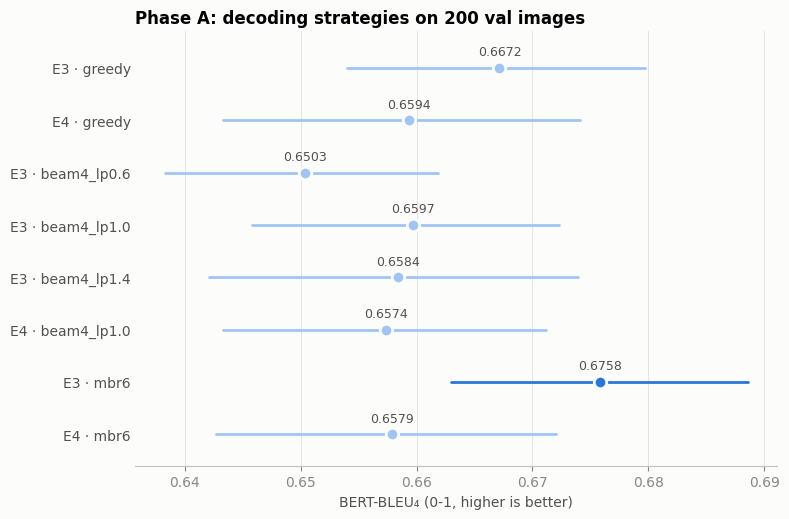

In [13]:
phase_a = pd.concat([greedy_table, beam_table, mbr_table])
phase_a.to_csv(OUT_DIR / 'phase_a_decoding.csv')
configs = [c for c in phase_a.index if c[0] != 'zero-shot']
ci_a = paired_bootstrap(configs, 'val', reference=('E3', 'greedy'))
ci_a.to_csv(OUT_DIR / 'phase_a_bootstrap.csv')

BEST_DECODING = ci_a['BERT-BLEU4'].idxmax()[1]
print('best decoding on val:', BEST_DECODING)
display(phase_a.round(4))
display(ci_a.round(4))
plot_ci(ci_a, f'Phase A: decoding strategies on {VAL_N} val images', 'phase_a_decoding.png')

## Phase B · Data scaling (after training E8)

Run this after `E8_full_data_train.ipynb` and re-run section 3 so the E8 adapters are loaded. Every checkpoint is scored with greedy
decoding, which gives BERT-BLEU₄ as a function of the number of training images seen. The x-positions come from the
checkpoint names; the ratio is exact because every checkpoint is saved at a fixed fraction of the run.

Caveat: the LR schedule is cosine, so an early checkpoint was also taken at a higher learning rate than the final one. The curve
mixes "more data" with "further along the schedule"; say so on the slide.

/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  E8@25%__greedy__val: 80/200
  E8@25%__greedy__val: 160/200
E8@25%__greedy__val: 1.06 s/image
  E8@50%__greedy__val: 80/200
  E8@50%__greedy__val: 160/200
E8@50%__greedy__val: 1.08 s/image
  E8@75%__greedy__val: 80/200
  E8@75%__greedy__val: 160/200
E8@75%__greedy__val: 1.07 s/image
  E8__greedy__val: 80/200
  E8__greedy__val: 160/200
E8__greedy__val: 1.09 s/image


,,split,BERT-BLEU4,geo P1-4,LP,BLEU-4,pred words,ref words,s/image,images seen
adapter,decoding,,,,,,,,,
E8@25%,greedy,val,0.6702,0.7850,0.8552,0.1043,45.045,47.96,1.0626,5066
E8@50%,greedy,val,0.6699,0.7803,0.8585,0.1017,43.145,47.96,1.0826,10132
E8@75%,greedy,val,0.6721,0.7890,0.8539,0.1058,44.545,47.96,1.0684,15198
E8,greedy,val,0.6700,0.7856,0.8535,0.1118,44.215,47.96,1.0879,20264


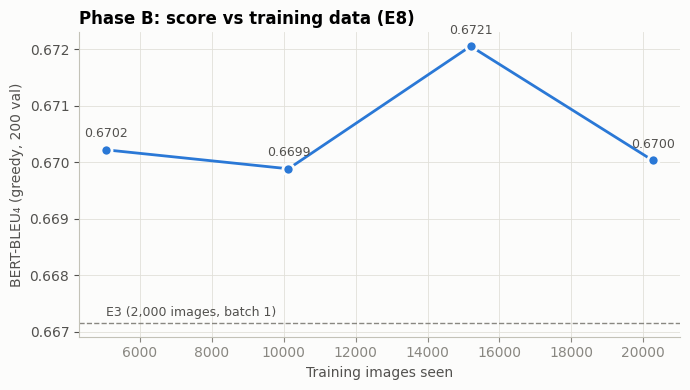

In [14]:
checkpoints = [n for n in LOADED if n.startswith('E8')]
if checkpoints:
    E8_TRAIN_IMAGES = json.loads(Path(ADAPTERS['E8']).parent.joinpath('metrics_E8.json').read_text())['config']['train_samples']
    frac = {n: (int(n.split('@')[1].rstrip('%')) / 100 if '@' in n else 1.0) for n in checkpoints}
    scaling = run([(n, 'greedy') for n in checkpoints])
    scaling['images seen'] = [round(frac[n] * E8_TRAIN_IMAGES) for n, _ in scaling.index]
    scaling = scaling.sort_values('images seen')
    scaling.to_csv(OUT_DIR / 'phase_b_scaling.csv')
    display(scaling.round(4))

    e3 = PER_IMAGE[('E3', 'greedy', 'val')].mean()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.axhline(e3, color=MUTED, lw=1, ls='--')
    ax.annotate('E3 (2,000 images, batch 1)', (scaling['images seen'].min(), e3), xytext=(0, 5),
                textcoords='offset points', fontsize=9, color=INK_2)
    ax.plot(scaling['images seen'], scaling['BERT-BLEU4'], '-o', color=BLUE, lw=2, ms=8, mec=SURFACE, mew=2)
    for x, y in zip(scaling['images seen'], scaling['BERT-BLEU4']):
        ax.annotate(f'{y:.4f}', (x, y), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9, color=INK_2)
    ax.set_xlabel('Training images seen')
    ax.set_ylabel(f'BERT-BLEU₄ (greedy, {VAL_N} val)')
    ax.set_title('Phase B: score vs training data (E8)')
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'phase_b_scaling.png', dpi=200)
    plt.show()
else:
    print('no E8 adapters loaded yet - train E8, then re-run section 3')

## Phase C · Final test (1000 held-out images)

The 200 val images were used to pick the decoding strategy and to compare checkpoints, so scores on them are slightly optimistic
(selection bias). The final comparison therefore uses 1000 images that were never used for any decision. With 5× more images, the
confidence interval is ~√5 ≈ 2.2× narrower.

/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  E3__greedy__test: 80/1000
  E3__greedy__test: 160/1000
  E3__greedy__test: 240/1000
  E3__greedy__test: 320/1000
  E3__greedy__test: 400/1000
  E3__greedy__test: 480/1000
  E3__greedy__test: 560/1000
  E3__greedy__test: 640/1000
  E3__greedy__test: 720/1000
  E3__greedy__test: 800/1000
  E3__greedy__test: 880/1000
  E3__greedy__test: 960/1000
E3__greedy__test: 1.07 s/image
  E8__greedy__test: 80/1000
  E8__greedy__test: 160/1000
  E8__greedy__test: 240/1000
  E8__greedy__test: 320/1000
  E8__greedy__test: 400/1000
  E8__greedy__test: 480/1000
  E8__greedy__test: 560/1000
  E8__greedy__test: 640/1000
  E8__greedy__test: 720/1000
  E8__greedy__test: 800/1000
  E8__greedy__test: 880/1000
  E8__greedy__test: 960/1000
E8__greedy__test: 1.09 s/image
E8__mbr6__test: 4.73 s/image


split  BERT-BLEU4  geo P1-4      LP  BLEU-4  pred words  \
adapter decoding                                                           
E3      greedy    test      0.6694    0.7810  0.8578  0.0969      46.008   
E8      greedy    test      0.6767    0.7894  0.8578  0.1102      45.408   
        mbr6      test      0.6860    0.7917  0.8675  0.1048      47.143   

                  ref words  s/image  
adapter decoding                      
E3      greedy       48.411   1.0726  
E8      greedy       48.411   1.0858  
        mbr6         48.411   4.7318

BERT-BLEU4  CI95 low  CI95 high  Δ vs E3/greedy  Δ CI95 low  \
adapter decoding                                                                
E3      greedy        0.6694    0.6629     0.6754          0.0000      0.0000   
E8      greedy        0.6767    0.6704     0.6832          0.0073      0.0015   
        mbr6          0.6860    0.6802     0.6918          0.0166      0.0114   

                  Δ CI95 high  P(best)  
adapter decoding                        
E3      greedy         0.0000      0.0  
E8      greedy         0.0129      0.0  
        mbr6           0.0220      1.0

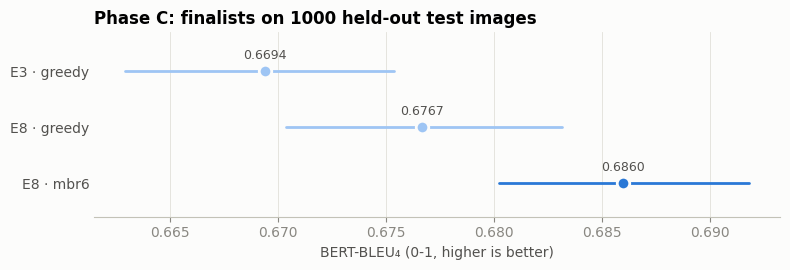

In [15]:
# Time on one T4 for 1000 images: greedy ~20 min, MBR ~80 min. MBR (best decoding on val) is tested on the final
# model only: E3 vs E8 (greedy) isolates the training change, E8 greedy vs E8 MBR isolates the decoding change.
FINALISTS = [('E3', 'greedy')]
if 'E8' in LOADED:
    FINALISTS += [('E8', 'greedy'), ('E8', BEST_DECODING)]
FINALISTS = list(dict.fromkeys(FINALISTS))   # drop duplicates if BEST_DECODING is greedy

phase_c = run(FINALISTS, split='test')
ci_c = paired_bootstrap(FINALISTS, 'test', reference=('E3', 'greedy'))
phase_c.to_csv(OUT_DIR / 'phase_c_test.csv')
ci_c.to_csv(OUT_DIR / 'phase_c_bootstrap.csv')
display(phase_c.round(4))
display(ci_c.round(4))
plot_ci(ci_c, f'Phase C: finalists on {TEST_N} held-out test images', 'phase_c_test.png')

## Export for `compare_experiments.ipynb`

Writes the chosen E8 configuration's **val** predictions (same 200 images as E0–E5, with correct image ids) into
`export/E8_model/`, together with its metrics file and adapter. Download that folder and put it into `models/` of the repo.

In [16]:
if 'E8' in LOADED:
    export = OUT_DIR / 'export' / 'E8_model'
    export.mkdir(parents=True, exist_ok=True)
    rows = predict('E8', BEST_DECODING, 'val')
    (export / 'predictions_E8.json').write_text(json.dumps(rows, indent=1, ensure_ascii=False))
    e8_dir = Path(ADAPTERS['E8'])
    for f in ['adapter_config.json', 'adapter_model.safetensors']:
        shutil.copy(e8_dir / f, export / f)
    shutil.copy(e8_dir.parent / 'metrics_E8.json', export / 'metrics_E8.json')
    print(f'exported E8 ({BEST_DECODING}) to {export}')
    for f in sorted(export.iterdir()):
        print('  -', f.name)

/usr/local/lib/python3.12/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


E8__mbr6__val: 4.68 s/image
exported E8 (mbr6) to /kaggle/working/decode_eval/export/E8_model
  - adapter_config.json
  - adapter_model.safetensors
  - metrics_E8.json
  - predictions_E8.json
